The next block discuss the stability of the second derivatives, as reviewer raises concern on the stability on the central difference method. Now says choose $x = 1, y = 0.5$, on different $h$ and $M$ and $n$，I will do 3 convergence analysis as evidence of the stability of the numerical result.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import pandas as pd

# 固定随机种子
np.random.seed(42)

# 模型参数
r = 0.03
kappa = 2.0
theta = 0.5
xi = 0.5

T = 1.0
t0 = 0.0
dt = (T - t0) / 100
N_steps = 100
N_paths = 50000

K = 1.0

# 提前生成布朗运动
Z1 = np.random.randn(N_paths, N_steps)
Z2 = np.random.randn(N_paths, N_steps)

In [2]:
def discounted_payoff_samples(x0, y0, z1, z2, n_steps):
    """Pathwise discounted payoffs, using the Euler scheme above."""
    n_paths = z1.shape[0]
    dt_test = (T - t0) / n_steps
    X = np.full(n_paths, x0, dtype=float)
    Y = np.full(n_paths, y0, dtype=float)

    for step in range(n_steps):
        dW1 = np.sqrt(dt_test) * z1[:, step]
        dW2 = np.sqrt(dt_test) * z2[:, step]
        Y = np.maximum(Y, 0)
        X = X + r * X * dt_test + np.sqrt(Y) * X * dW1
        Y = Y + kappa * (theta - Y) * dt_test + xi * np.sqrt(Y) * dW2

    payoff = np.maximum(K - X, 0)
    return np.exp(-r * (T - t0)) * payoff


def estimate_vyy(h, z1, z2, n_steps):
    """Estimate the central second difference and paired-path MC standard error."""
    if h <= 0 or y_test - h <= 0:
        raise ValueError(f"h must be positive and y-h must remain positive; got h={h}")
    if z1.shape != z2.shape or z1.shape[1] < n_steps:
        raise ValueError("Brownian arrays must have matching shapes and enough time steps")

    payoff_minus = discounted_payoff_samples(x_test, y_test - h, z1, z2, n_steps)
    payoff_center = discounted_payoff_samples(x_test, y_test, z1, z2, n_steps)
    payoff_plus = discounted_payoff_samples(x_test, y_test + h, z1, z2, n_steps)
    pathwise_vyy = (payoff_plus - 2 * payoff_center + payoff_minus) / h**2
    return pathwise_vyy.mean(), pathwise_vyy.std(ddof=1) / np.sqrt(len(pathwise_vyy))


# Convergence/stability tests for V_yy at x=1 and y=0.5.
# The same Brownian paths are used at y-h, y, and y+h (common random numbers).

x_test = 1.0
y_test = 0.5

In [3]:
# h test: use the spacing of np.linspace(0.01, 1.0, K).
# The exact spacing is 0.99/(K-1), approximately 1/K for larger K.
K_grid_counts = [5, 10, 20, 40, 80]
h_rows = []
for K_grid in K_grid_counts:
    y_grid_test = np.linspace(0.01, 1.0, K_grid)
    h_test = y_grid_test[1] - y_grid_test[0]
    estimate, mc_se = estimate_vyy(h_test, Z1, Z2, N_steps)
    h_rows.append({"K": K_grid, "h": h_test, "V_yy": estimate, "MC_SE": mc_se})
h_results = pd.DataFrame(h_rows)
h_results["abs_diff_from_finest"] = np.abs(h_results["V_yy"] - h_results["V_yy"].iloc[-1])

# M test: vary N_paths; keep the time discretization and h fixed.
M_values = [500, 1000, 2500, 5000, 10000, 45000]
y_grid_for_h = np.linspace(0.01, 1.0, 25)
h_fixed = y_grid_for_h[1] - y_grid_for_h[0]
if Z1.shape[0] < max(M_values) or Z1.shape[1] < N_steps:
    raise ValueError("Existing Z1/Z2 arrays are too small for the requested M convergence test")
M_rows = []
for M_test in M_values:
    estimate, mc_se = estimate_vyy(h_fixed, Z1[:M_test, :N_steps], Z2[:M_test, :N_steps], N_steps)
    M_rows.append({"M (N_paths)": M_test, "h": h_fixed, "n (N_steps)": N_steps, "V_yy": estimate, "MC_SE": mc_se})
M_results = pd.DataFrame(M_rows)
M_results["abs_diff_from_largest_M"] = np.abs(M_results["V_yy"] - M_results["V_yy"].iloc[-1])

# # n test: use independent standard-normal increments at each resolution.
# # This allows arbitrary n values without requiring divisibility by n_max.
# n_values = [10, 20, 30, 50, 70, 100, 130, 150, 200]
# M_fixed = 50000
# rng = np.random.default_rng(20261104)
# n_rows = []
# for n_test in n_values:
#     Z1_n = rng.standard_normal((M_fixed, n_test))
#     Z2_n = rng.standard_normal((M_fixed, n_test))
#     estimate, mc_se = estimate_vyy(h_fixed, Z1_n, Z2_n, n_test)
#     n_rows.append({"n (N_steps)": n_test, "M (N_paths)": M_fixed, "h": h_fixed, "V_yy": estimate, "MC_SE": mc_se})
# n_results = pd.DataFrame(n_rows)
# n_results["abs_diff_from_finest_n"] = np.abs(n_results["V_yy"] - n_results["V_yy"].iloc[-1])

print("h convergence (M={}, n={}):".format(N_paths, N_steps))
print(h_results.to_string(index=False, float_format=lambda value: f"{value:.6g}"))
print("\nM convergence (fixed h and n):")
print(M_results.to_string(index=False, float_format=lambda value: f"{value:.6g}"))
# print("\nn convergence (fixed h and M):")
# print(n_results.to_string(index=False, float_format=lambda value: f"{value:.6g}"))

# all_vyy_estimates = np.concatenate((h_results["V_yy"].to_numpy(), M_results["V_yy"].to_numpy(), n_results["V_yy"].to_numpy()))
# max_abs_vyy = np.max(np.abs(all_vyy_estimates))
# if max_abs_vyy > 0:
#     magnitude_order = int(np.floor(np.log10(max_abs_vyy)))
#     print(f"\nMagnitude check: max |V_yy| across all tests = {max_abs_vyy:.3e} (order 10^{magnitude_order}).")
# else:
#     print("\nMagnitude check: all V_yy estimates are zero.")

h convergence (M=50000, n=100):
 K         h       V_yy       MC_SE  abs_diff_from_finest
 5    0.2475  -0.054858 0.000973168            0.00388546
10      0.11 -0.0546111  0.00119938             0.0036386
20 0.0521053 -0.0541294   0.0016198            0.00315688
40 0.0253846 -0.0520327  0.00228831            0.00106017
80 0.0125316 -0.0509725  0.00313524                     0

M convergence (fixed h and n):
 M (N_paths)       h  n (N_steps)       V_yy      MC_SE  abs_diff_from_largest_M
         500 0.04125          100 -0.0722329  0.0080526                0.0180082
        1000 0.04125          100 -0.0647808 0.00995572                 0.010556
        2500 0.04125          100 -0.0585071 0.00729393               0.00428237
        5000 0.04125          100 -0.0569514 0.00547071               0.00272666
       10000 0.04125          100  -0.053982 0.00396839              0.000242728
       45000 0.04125          100 -0.0542247 0.00188642                        0


In [4]:
# Common Brownian paths across different time resolutions
n_values = [10, 20, 25, 50, 100]

M_fixed = N_paths
N_max = N_steps

n_rows = []

for n_test in n_values:
    m = N_max // n_test

    Z1_n = Z1.reshape(M_fixed, n_test, m).sum(axis=2) / np.sqrt(m)
    Z2_n = Z2.reshape(M_fixed, n_test, m).sum(axis=2) / np.sqrt(m)

    estimate, mc_se = estimate_vyy(h_fixed, Z1_n, Z2_n, n_test)

    n_rows.append({
        "n (N_steps)": n_test,
        "M (N_paths)": M_fixed,
        "h": h_fixed,
        "V_yy": estimate,
        "MC_SE": mc_se
    })

n_results = pd.DataFrame(n_rows)

n_results["abs_diff_from_finest_n"] = np.abs(
    n_results["V_yy"] - n_results["V_yy"].iloc[-1]
)

print(n_results.to_string(index=False))

 n (N_steps)  M (N_paths)       h      V_yy    MC_SE  abs_diff_from_finest_n
          10        50000 0.04125 -0.049125 0.002506                0.004441
          20        50000 0.04125 -0.049167 0.002129                0.004400
          25        50000 0.04125 -0.052678 0.001949                0.000888
          50        50000 0.04125 -0.052989 0.001844                0.000577
         100        50000 0.04125 -0.053566 0.001810                0.000000


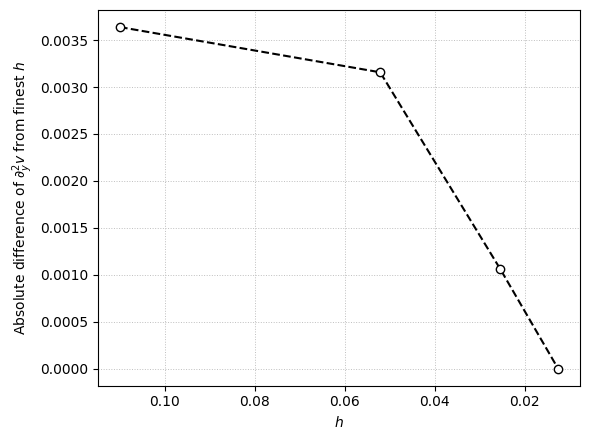

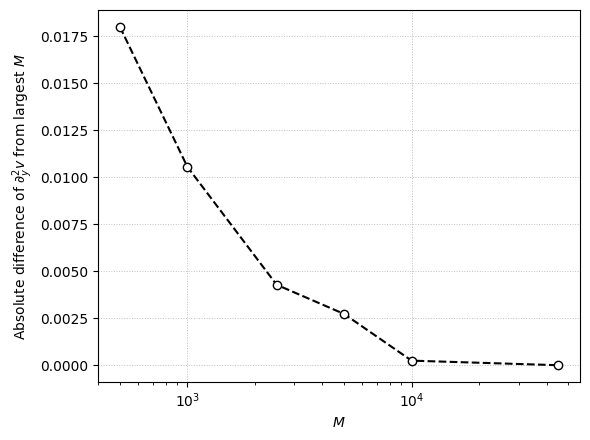

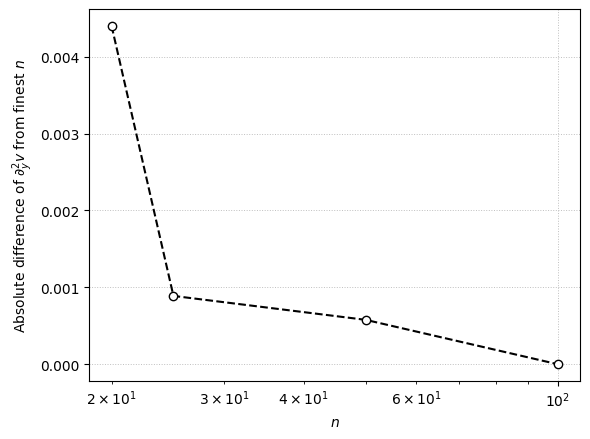

In [5]:
plot_style = {"color": "black", "linestyle": "--", "marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}

fig, ax = plt.subplots(figsize=(6, 4.5), facecolor="white")
ax.plot(h_results["h"][1:], h_results["abs_diff_from_finest"][1:], **plot_style)
ax.set_xlabel("$h$")
ax.invert_xaxis()
ax.set_ylabel("Absolute difference of $\partial^2_y v$ from finest $h$")
ax.set_facecolor("white")
ax.grid(True, color="0.75", linestyle=":", linewidth=0.7)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5), facecolor="white")
ax.plot(M_results["M (N_paths)"], M_results["abs_diff_from_largest_M"], **plot_style)
ax.set_xscale("log")
ax.set_xlabel("$M$")
ax.set_ylabel("Absolute difference of $\partial^2_y v$ from largest $M$")
ax.set_facecolor("white")
ax.grid(True, color="0.75", linestyle=":", linewidth=0.7)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5), facecolor="white")
ax.plot(n_results["n (N_steps)"][1:], n_results["abs_diff_from_finest_n"][1:], **plot_style)
ax.set_xscale("log")
ax.set_xlabel("$n$")
ax.set_ylabel("Absolute difference of $\partial^2_y v$ from finest $n$")
ax.set_facecolor("white")
ax.grid(True, color="0.75", linestyle=":", linewidth=0.7)
fig.tight_layout()
plt.show()